# E-cell manual fit
Simulate E_cell for a chosen test, compare against experiment, and inspect the cathode electrolyte-potential profile at the final time-step of each current-density point.\
**Workflow:** edit the *Parameters* cell -> run all -> read the plots.

In [ ]:
import sys, os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).resolve()
while not (PROJECT_ROOT / 'setup.py').exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError('Cannot find project root')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from solve_dae.integrate import solve_dae

ROOT = Path("../..").resolve()
sys.path.insert(0, str(ROOT / "scripts" / "Experimental"))

from simulate_HFR import build_cell, build_atol, soc_cutoff_event  # noqa: E402
from rfbmodel1D.parameters.params import cathodeparams, anodeparams, membraneparams, cellparams  # noqa: E402


## -- Parameters -- 

In [ ]:
# -- test selection ------------------------------------------------------------
TEST_NO = 1    # integer 1-29

# Path relative to scripts/Experimental/fit_results/, or None to use defaults
fit_dir  = ROOT / "results" / "test fitting" / f"test {TEST_NO}"
HFR_FIT  = sorted(fit_dir.glob(f"fit_v2_test{TEST_NO}_*.json"))[-1].name

# -- electrode kinetics (hand-tuned) -------------------------------------------
k_ca    = 8.458464713253994e-07  # cathode reaction rate constant   [m/s]
j0_an   = 901.1613907780675  # anode exchange current density   [A/m²]

# -- solver settings -----------------------------------------------------------
TF     = 1800    # simulation duration per point [s]
RTOL   = 1e-4    # relative tolerance for time integration
STRIDE_charg = 1 # use every Nth current-density point (1 = all)
STRIDE_disch = 1 # use every Nth point for discharge (to speed up discharge simulation, which is slower due to more points and lower currents)

In [ ]:
if HFR_FIT is not None:
    with open(fit_dir / HFR_FIT) as f:
        _hfr = json.load(f)
    _p = _hfr["params"]
    membraneparams.k_sorp_vw   = _p["k_vw_sorp"]
    membraneparams.k_desorp_vw = _p["S_desorp"] * _p["k_vw_sorp"]
    membraneparams.k_sorp_lw   = _p["k_lw_sorp"]
    membraneparams.k_desorp_lw = _p["S_desorp"] * _p["k_lw_sorp"]
    membraneparams.k_ca_lw     = _p["k_ca"]
    membraneparams.sf_D        = 0.5
    cellparams.vanadium_uptake = False
    print(f"Membrane params loaded from: {HFR_FIT}")

# -- apply hand-tuned electrode kinetics --------------------------------------
cathodeparams.reaction_rate_constant = k_ca/10
anodeparams.j_0                      = j0_an

# -- load experimental data ---------------------------------------------------
csv  = ROOT / "data" / "experimental" / "E_cell.csv"
data = pd.read_csv(csv)
data = data[data["test_no"] == TEST_NO]

soc = data["SOC"].iloc[0]      # % (state of charge)
T   = data["T(°C)"].iloc[0]        # °C
Q_v = data["Q_v (ml/min)"].iloc[0] # ml/min

j_charge    = data[data["mode"] == "charge"]["j_appl (A/m2)"].values[::STRIDE_charg]
j_discharge = data[data["mode"] == "discharge"]["j_appl (A/m2)"].values[::STRIDE_disch]
E_exp       = np.concatenate([
    data[data["mode"] == "charge"]["value (V)"].values[::STRIDE_charg],
    data[data["mode"] == "discharge"]["value (V)"].values[::STRIDE_disch],
])
print(f"Test {TEST_NO}: SOC={soc}, T={T}°C, Q_v={Q_v} ml/min, k_ca={k_ca:.4e} m/s, j0_an={j0_an:.4e} A/m²")
print(f"Charge points: {len(j_charge)}   Discharge points: {len(j_discharge)}")

## Run simulations

In [ ]:
def run_sim(j_appl: float):
    '''Run one DAE solve.  Returns (E_cell [V], Phi_el_profile [V], x_ca [Nc]).'''
    cell, y0, yp0 = build_cell(soc, j_appl, T, Q_v)
    atol = build_atol(cell)
    t0   = time.time()
    jac_sparsity = cell.compute_jac_sparsity(y0, yp0)
    sol  = solve_dae(
        cell.dae_residual_full_cell,
        (0.0, TF), y0, yp0,
        method="BDF", atol=atol, rtol=RTOL,
        events=soc_cutoff_event, jac_sparsity=jac_sparsity
    )
    elapsed = time.time() - t0

    # -- electrolyte-potential profile at final timestep ---------------------
    y_final        = sol.y[:, -1]
    Nc             = cell.mesh.cathode_mesh.n_x
    n_vars_cathode = cell.layout.n_vars_cathode
    n_vars_tank    = cell.layout.n_vars_tank
    offset_cathode = n_vars_tank
    Phi_el_profile = y_final[offset_cathode:offset_cathode + Nc * n_vars_cathode].reshape(Nc, n_vars_cathode)[:, 4]
    x_ca           = cell.mesh.cathode_mesh.x_grid    # normalised 0->1

    # -- E_cell ---------------------------------------------------------------
    dx       = cell.mesh.cathode_mesh.dx[0] * cell.cathode.thickness
    sigma_el = cell.cathode.eff_conductivity
    E_cell   = float(Phi_el_profile[0] + j_appl * (dx / 2) / sigma_el)

    print(f"  j={j_appl:+8.0f} A/m2  E_cell={E_cell:.4f} V  ({elapsed:.1f}s)")
    return E_cell, Phi_el_profile, x_ca


E_sim      = []
phi_charge = []
phi_disc   = []
x_ca_ref   = None   # will be set on first solve (same grid for all)

print("=== Charge ===")
for i in range(len(j_charge)):
    j = j_charge[i]
    e_cell, phi, x_ca = run_sim(float(j))
    E_sim.append(e_cell);  phi_charge.append(phi);  x_ca_ref = x_ca

print("=== Discharge ===")
for i in range(len(j_discharge)):
    j = j_discharge[i]
    e_cell, phi, x_ca = run_sim(-float(j))
    E_sim.append(e_cell);  phi_disc.append(phi)

mse = float(np.mean((np.array(E_sim) - E_exp) ** 2))
print(f"MSE = {mse:.6f} V^2")

## Results

In [ ]:
# -- E_cell: simulated vs experimental -----------------------------------------
nc, nd = len(j_charge), len(j_discharge)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(j_charge,    E_sim[:nc],  'b-o',  lw=2, ms=6, label='Charge (sim)')
ax.plot(j_discharge, E_sim[nc:],  'r-o',  lw=2, ms=6, label='Discharge (sim)')
ax.plot(j_charge,    E_exp[:nc],  'b^--', lw=1.5, ms=7, mfc='none', label='Charge (exp)')
ax.plot(j_discharge, E_exp[nc:],  'r^--', lw=1.5, ms=7, mfc='none', label='Discharge (exp)')
ax.set_xlabel('Applied current density  [A/m²]')
ax.set_ylabel('Cell voltage  [V]')
ax.set_title(
    f'Test {TEST_NO}  |  SOC={soc}  T={T}°C  Q_v={Q_v} ml/min\n'
    f'k_ca={k_ca:.4e} m/s   j0_an={j0_an:.4e} A/m²   MSE={mse:.4f}'
)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

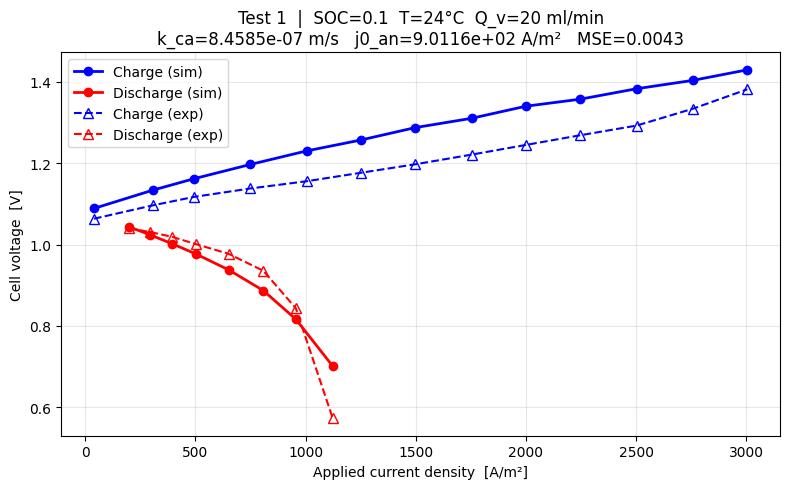

In [ ]:
# -- Cathode electrolyte-potential profiles at final time ---------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

colors_c = plt.cm.Blues(np.linspace(0.4, 0.95, max(nc, 1)))
for phi, j, c in zip(phi_charge, j_charge, colors_c):
    axes[0].plot(x_ca_ref, phi, color=c, lw=2, label=f'{j:.0f} A/m²')
axes[0].set_xlabel('Normalised cathode position  x / –')
axes[0].set_ylabel('Electrolyte potential  Φ$_{el}$  [V]')
axes[0].set_title('Charge')
axes[0].legend(fontsize=7, loc='best')
axes[0].grid(True, alpha=0.3)

colors_d = plt.cm.Reds(np.linspace(0.4, 0.95, max(nd, 1)))
for phi, j, c in zip(phi_disc, j_discharge, colors_d):
    axes[1].plot(x_ca_ref, phi, color=c, lw=2, label=f'{j:.0f} A/m²')
axes[1].set_xlabel('Normalised cathode position  x / –')
axes[1].set_title('Discharge')
axes[1].legend(fontsize=7, loc='best')
axes[1].grid(True, alpha=0.3)

fig.suptitle(
    f'Φ$_{{el}}$ profile at t = {TF} s  |  Test {TEST_NO}  SOC={soc}\n'
    f'k_ca={k_ca:.4e} m/s   j0_an={j0_an:.4e} A/m²   MSE={mse:.4f}',
    fontsize=11
)
plt.tight_layout()
plt.show()